# Mineral chemistry setup check

Configure PhreeqcMatlab as described in the installation guide: native IPhreeqc on Linux or COM on Windows. MRST owns flow and transport; PHREEQC owns local microbial kinetics and chemistry in the coupled cases. This short check uses four cells and two injection timesteps. It compares a microbial biochemistry baseline with three mineral inventories; differences from the baseline also reflect different reaction backends. Hydrogen consumption is reported in mol. The default MATLAB example uses 50 cells and the complete 50-day injection schedule.

In [ ]:
startupH2sim('phreeqc', true)
comparison = exampleCompositionalBacterial1DPhreeqcMinerals( ...
    'gridCells', 4, 'maximumFlowSteps', 2, 'plotResults', false);
state = comparison(2).states{end};
pH = state.phreeqcPH;
elementChecks = state.phreeqcElementBalancePass;

% Redraw accepted states without solving again.
plotPhreeqcMineralComparison(comparison, ...
    'outputDirectory', fullfile(pwd, 'build', 'example-figures'));

## Read the plots

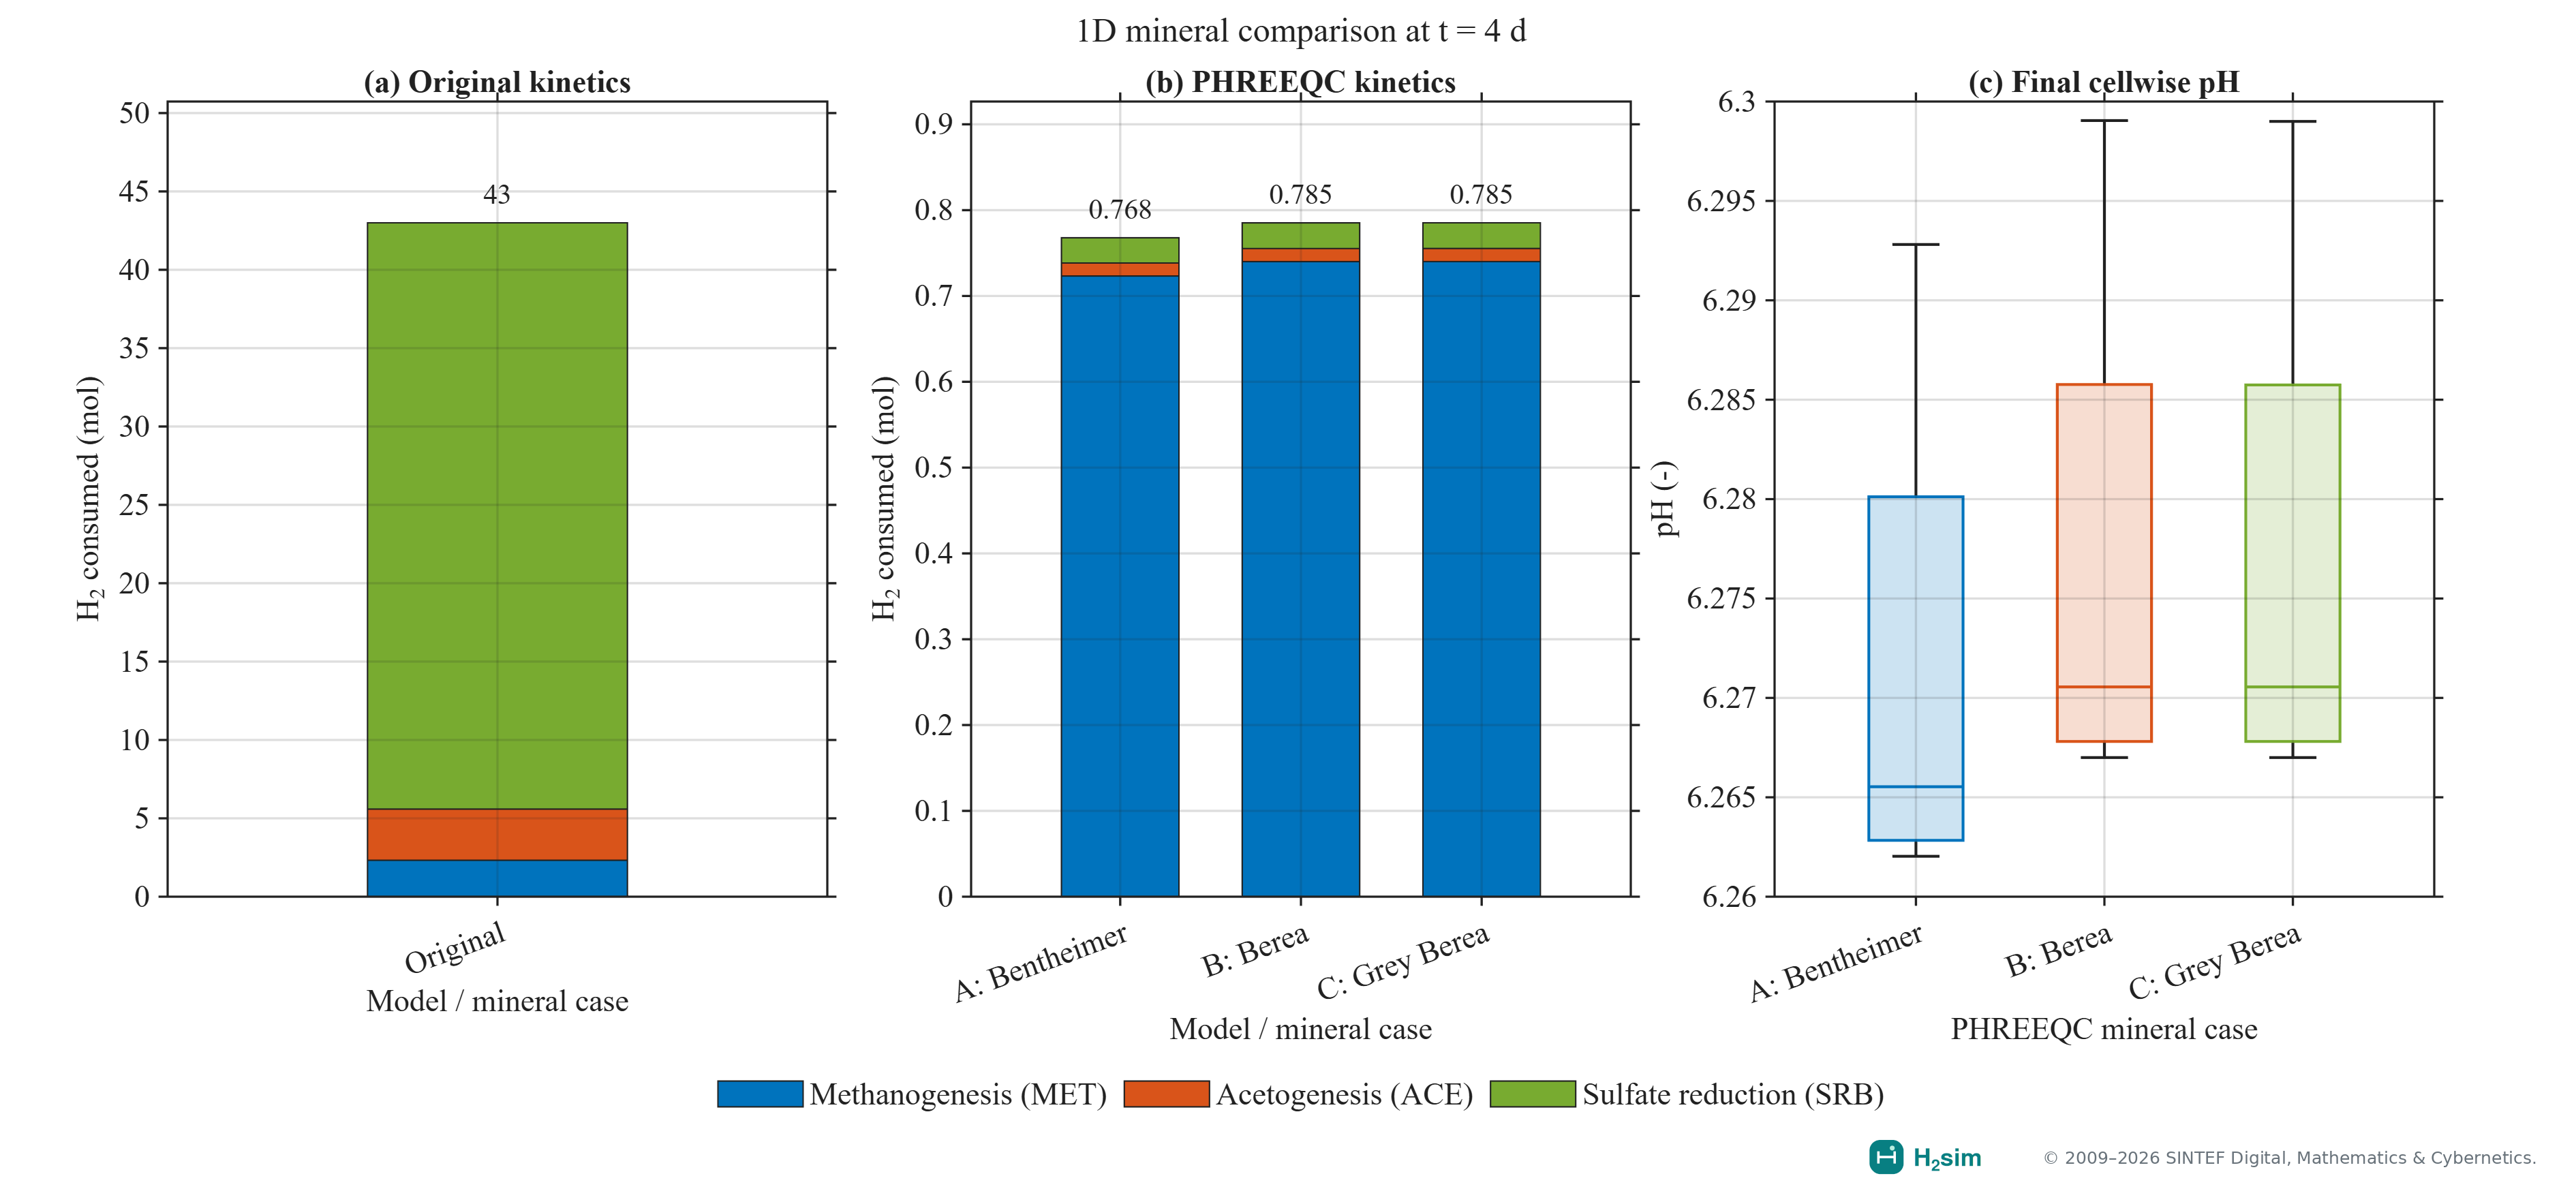

The microbial biochemistry baseline and PHREEQC cases have different kinetic owners. Their differences are not a pure mineral effect. The baseline has no PHREEQC pH. Check the elemental audit and evaluated-cell mask before interpreting chemistry output.

`comparison(k).states` retains the state history. The example uses packed simulation output, allowing accepted results to be replotted.